In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/devildyno/computer-science-students-career-prediction/cs_students.csv


In [2]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings("ignore")

In [3]:
data=pd.read_csv('/kaggle/input/datasets/devildyno/computer-science-students-career-prediction/cs_students.csv')
data.head()  


,Student ID,Name,Gender,Age,GPA,Major,Interested Domain,Projects,Future Career,Python,SQL,Java
0,1,John Smith,Male,21,3.5,Computer Science,Artificial Intelligence,Chatbot Development,Machine Learning Researcher,Strong,Strong,Weak
1,2,Alice Johnson,Female,20,3.2,Computer Science,Data Science,Data Analytics,Data Scientist,Average,Strong,Weak
2,3,Robert Davis,Male,22,3.8,Computer Science,Software Development,E-commerce Website,Software Engineer,Strong,Strong,Average
3,4,Emily Wilson,Female,21,3.7,Computer Science,Web Development,Full-Stack Web App,Web Developer,Weak,Strong,Strong
4,5,Michael Brown,Male,23,3.4,Computer Science,Cybersecurity,Network Security,Information Security Analyst,Average,Weak,Strong


In [4]:
data.info()
data.isnull().sum()
data.duplicated().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Student ID         180 non-null    int64  
 1   Name               180 non-null    object 
 2   Gender             180 non-null    object 
 3   Age                180 non-null    int64  
 4   GPA                180 non-null    float64
 5   Major              180 non-null    object 
 6   Interested Domain  180 non-null    object 
 7   Projects           180 non-null    object 
 8   Future Career      180 non-null    object 
 9   Python             180 non-null    object 
 10  SQL                180 non-null    object 
 11  Java               180 non-null    object 
dtypes: float64(1), int64(2), object(9)
memory usage: 17.0+ KB


np.int64(0)

In [5]:
data.describe()

,Student ID,Age,GPA
count,180.000000,180.000000,180.000000
mean,90.500000,22.116667,3.615000
std,52.105662,2.823040,0.177341
min,1.000000,20.000000,3.200000
25%,45.750000,21.000000,3.500000
50%,90.500000,22.000000,3.600000
75%,135.250000,22.250000,3.700000
max,180.000000,37.000000,3.900000


In [6]:
data["Age"]=pd.to_numeric(data["Age"])



In [7]:
#category value check
data["Interested Domain"].value_counts()

Interested Domain
Artificial Intelligence           19
Web Development                   19
Cybersecurity                     18
Mobile App Development            17
Database Management               16
Cloud Computing                   16
Data Science                      13
Computer Graphics                 13
Machine Learning                  13
Software Development              11
Software Engineering               5
Bioinformatics                     2
Human-Computer Interaction         2
Quantum Computing                  2
Biomedical Computing               2
Computer Vision                    1
IoT (Internet of Things)           1
Game Development                   1
Network Security                   1
Data Mining                        1
Natural Language Processing        1
Blockchain Technology              1
Information Retrieval              1
Data Privacy                       1
Geographic Information Systems     1
Distributed Systems                1
Digital Forensics   

In [8]:
#category value check
data["Gender"].value_counts()

Gender
Male      102
Female     78
Name: count, dtype: int64

In [9]:
#Encode categorical data
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
data["Gender"]=le.fit_transform(data["Gender"])
data["Major"]=le.fit_transform(data["Major"])
data["Interested Domain"]=le.fit_transform(data["Interested Domain"])



In [10]:
data.info()
data.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Student ID         180 non-null    int64  
 1   Name               180 non-null    object 
 2   Gender             180 non-null    int64  
 3   Age                180 non-null    int64  
 4   GPA                180 non-null    float64
 5   Major              180 non-null    int64  
 6   Interested Domain  180 non-null    int64  
 7   Projects           180 non-null    object 
 8   Future Career      180 non-null    object 
 9   Python             180 non-null    object 
 10  SQL                180 non-null    object 
 11  Java               180 non-null    object 
dtypes: float64(1), int64(5), object(6)
memory usage: 17.0+ KB


,Student ID,Name,Gender,Age,GPA,Major,Interested Domain,Projects,Future Career,Python,SQL,Java
0,1,John Smith,1,21,3.5,0,0,Chatbot Development,Machine Learning Researcher,Strong,Strong,Weak
1,2,Alice Johnson,0,20,3.2,0,10,Data Analytics,Data Scientist,Average,Strong,Weak
2,3,Robert Davis,1,22,3.8,0,24,E-commerce Website,Software Engineer,Strong,Strong,Average
3,4,Emily Wilson,0,21,3.7,0,26,Full-Stack Web App,Web Developer,Weak,Strong,Strong
4,5,Michael Brown,1,23,3.4,0,7,Network Security,Information Security Analyst,Average,Weak,Strong


In [11]:
import pandas as pd
df=pd.read_csv("/kaggle/input/datasets/devildyno/computer-science-students-career-prediction/cs_students.csv")


In [12]:
import sqlite3
conn=sqlite3.connect("students.db")
df.to_sql("students",conn,if_exists="replace",index=False)
pd.read_sql_query("select * FROM students LIMIT 5",conn)

,Student ID,Name,Gender,Age,GPA,Major,Interested Domain,Projects,Future Career,Python,SQL,Java
0,1,John Smith,Male,21,3.5,Computer Science,Artificial Intelligence,Chatbot Development,Machine Learning Researcher,Strong,Strong,Weak
1,2,Alice Johnson,Female,20,3.2,Computer Science,Data Science,Data Analytics,Data Scientist,Average,Strong,Weak
2,3,Robert Davis,Male,22,3.8,Computer Science,Software Development,E-commerce Website,Software Engineer,Strong,Strong,Average
3,4,Emily Wilson,Female,21,3.7,Computer Science,Web Development,Full-Stack Web App,Web Developer,Weak,Strong,Strong
4,5,Michael Brown,Male,23,3.4,Computer Science,Cybersecurity,Network Security,Information Security Analyst,Average,Weak,Strong


In [13]:
#total students
query="""SELECT COUNT(*) AS Total_Students FROM students"""
pd.read_sql_query(query, conn)

,Total_Students
0,180


In [14]:
#Average GPA
query="""SELECT ROUND(AVG(GPA),2) AS  Avg_GPA FROM students"""
pd.read_sql_query(query,conn)

,Avg_GPA
0,3.62


In [15]:
#Gender distribuition
query="""SELECT Gender,COUNT(*) AS Total FROM students GROUP BY Gender"""
pd.read_sql_query(query,conn)


,Gender,Total
0,Female,78
1,Male,102


In [16]:
#Average GPA by gender
query="""SELECT Gender,ROUND(AVG(GPA),2) AS AVG_GPA FROM students GROUP BY Gender"""
pd.read_sql_query(query,conn)

,Gender,AVG_GPA
0,Female,3.63
1,Male,3.60


In [17]:
#Top 10 students by GPA
query="""SELECT Name,GPA FROM students ORDER BY GPA DESC LIMIT 10"""
pd.read_sql_query(query,conn)

,Name,GPA
0,Laura Lee,3.9
1,Laura Lee,3.9
2,Laura Lee,3.9
3,Laura Lee,3.9
4,Agent Coulson,3.9
5,Agent Fitz,3.9
6,Michael Brown,3.9
7,Laura Lee,3.9
8,Laura Lee,3.9
9,Olivia Davis,3.9


In [18]:
pd.read_sql_query("PRAGMA table_info(students)",conn)

,cid,name,type,notnull,dflt_value,pk
0,0,Student ID,INTEGER,0,None,0
1,1,Name,TEXT,0,None,0
2,2,Gender,TEXT,0,None,0
3,3,Age,INTEGER,0,None,0
4,4,GPA,REAL,0,None,0
5,5,Major,TEXT,0,None,0
6,6,Interested Domain,TEXT,0,None,0
7,7,Projects,TEXT,0,None,0
8,8,Future Career,TEXT,0,None,0
9,9,Python,TEXT,0,None,0


In [19]:
query = """
SELECT "Interested Domain",
       COUNT(*) AS Total_Students
FROM students
GROUP BY "Interested Domain"
ORDER BY COUNT(*) DESC
"""

pd.read_sql_query(query, conn)

,Interested Domain,Total_Students
0,Web Development,19
1,Artificial Intelligence,19
2,Cybersecurity,18
3,Mobile App Development,17
4,Database Management,16
5,Cloud Computing,16
6,Machine Learning,13
7,Data Science,13
8,Computer Graphics,13
9,Software Development,11


In [20]:
#highest GPA students
query="""SELECT Name,GPA FROM students ORDER BY GPA DESC LIMIT 1"""
pd.read_sql_query(query, conn)

,Name,GPA
0,Laura Lee,3.9


In [21]:
#AVERAGE GPA BY DOMAIN
query="""SELECT "Interested Domain",ROUND(AVG(GPA),2) AS AVG_GPA FROM students GROUP BY "Interested Domain" ORDER BY AVG_GPA DESC"""
pd.read_sql_query(query, conn)

,Interested Domain,AVG_GPA
0,Natural Language Processing,3.90
1,Distributed Systems,3.90
2,Software Engineering,3.80
3,Quantum Computing,3.80
4,Data Privacy,3.80
5,Machine Learning,3.75
6,Network Security,3.70
7,Bioinformatics,3.70
8,Cloud Computing,3.68
9,Artificial Intelligence,3.68


In [22]:
#GPA category analysis
query="""
SELECT
CASE
    WHEN GPA >= 3.5 THEN "Excellent"
     WHEN GPA >= 3.0 THEN "Good"
     ELSE "Average"
END AS GPA_Category,
COUNT(*) AS students
FROM students
GROUP BY GPA_Category
"""
pd.read_sql_query(query, conn)

,GPA_Category,students
0,Excellent,150
1,Good,30


In [23]:
#SQL skill analysis
query="""
SELECT SQL,COUNT(*) AS Total
FROM students
GROUP BY SQL
LIMIT 5
"""
pd.read_sql_query(query, conn)
pd.read_sql_query(query, conn)

,SQL,Total
0,Average,60
1,Strong,79
2,Weak,41


In [24]:
#Python skill analysis
query="""
SELECT Python,COUNT(*) AS Total
FROM students
GROUP BY Python
LIMIT 5
"""
pd.read_sql_query(query, conn)

,Python,Total
0,Average,46
1,Strong,70
2,Weak,64


In [25]:
#Java skill analysis
query="""SELECT Java,COUNT(*) AS Total
FROM students
GROUP BY Java
LIMIT 5
"""
pd.read_sql_query(query, conn)

,Java,Total
0,Average,47
1,Strong,69
2,Weak,64


In [26]:
#Average python score
query = """
SELECT
ROUND(AVG(
    CASE
        WHEN Python='Weak' THEN 1
        WHEN Python='Average' THEN 2
        WHEN Python='Strong' THEN 3
    END
),2) AS Avg_Python_Score
FROM students
"""

pd.read_sql_query(query, conn)


,Avg_Python_Score
0,2.03


In [27]:
#averagesql score
query = """
SELECT
ROUND(AVG(
    CASE
        WHEN SQL='Weak' THEN 1
        WHEN SQL='Average' THEN 2
        WHEN SQL='Strong' THEN 3
    END
),2) AS Avg_sql_Score
FROM students
"""

pd.read_sql_query(query, conn)


,Avg_sql_Score
0,2.21


In [28]:
#average java score
query = """
SELECT
ROUND(AVG(
    CASE
        WHEN Java='Weak' THEN 1
        WHEN Java='Average' THEN 2
        WHEN Java='Strong' THEN 3
    END
),2) AS Avg_Java_Score
FROM students
"""

pd.read_sql_query(query, conn)


,Avg_Java_Score
0,2.03


In [29]:
#.................INSIGHTS............
#.................Student Demographics..................
#The dataset contains information on computer science students with diverse academic interests and career aspirations.
#Male and female students are both represented, providing a balanced view of student preferences.

#...........................GPA Analysis............................
#Students with higher GPAs tend to show interest in specialized domains such as Artificial Intelligence and Data Science.
#The average GPA indicates that most students maintain satisfactory academic performance.

#..................Domain Interest Analysis.............
#Artificial Intelligence, Data Science, and Web Development are among the most popular domains.
#Some domains attract significantly more students than others, reflecting current industry trends.

#....................................Skill Analysis....................
#SQL and Python are among the most common technical strengths across students.
#A large proportion of students possess Average to Strong programming skills.
#Java proficiency varies more widely compared to Python and SQL.

#............................Career Aspiration Analysis.........................
#Students' future career goals are strongly aligned with their interested domains.
#For example, students interested in Data Science often aspire to become Data Scientists, while AI-focused students aim for Machine Learning or AI-related roles.

#.............................Project Analysis..........................
#Students who completed domain-specific projects generally show matching career interests.
#Practical project experience appears to support clearer career direction.

In [30]:
import pandas as pd
import matplotlib.pyplot as plt


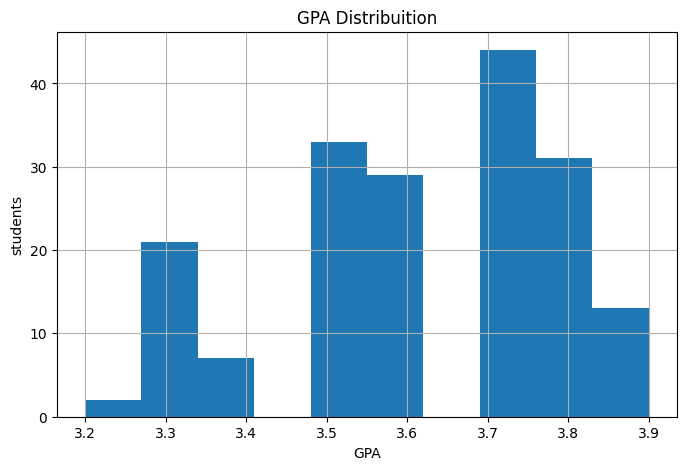

In [31]:
#GPA Distribuition
plt.figure(figsize=(8,5))
df["GPA"].hist(bins=10)

plt.title("GPA Distribuition")
plt.xlabel("GPA")
plt.ylabel("students")
plt.show()
#most students have GPAs concentrated in the middel to high range

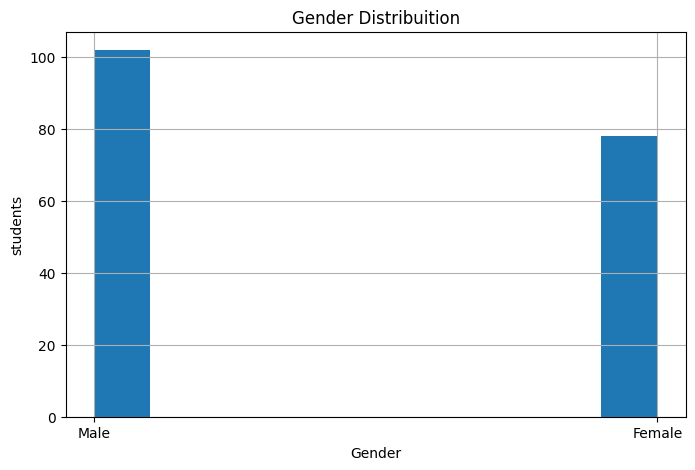

In [32]:
#Gender Distribuition
plt.figure(figsize=(8,5))
df["Gender"].hist(bins=10)

plt.title("Gender Distribuition")
plt.xlabel("Gender")
plt.ylabel("students")
plt.show()
#male students with the highest bar represents the majority of student

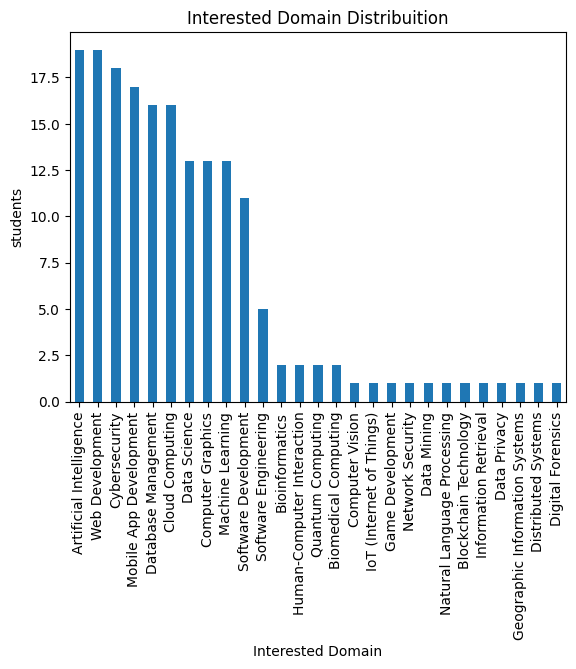

'The distribution shows that Artificial Intelligence, Web Development, Cybersecurity, and \nData Analytics are the most popular domains among students. In contrast, specialized fields \nsuch as Blockchain Technology, Data Privacy, Digital Forensics, and Distributed Systems\nattract relatively fewer students. This suggests that students are more inclined toward \nhigh-demand and rapidly growing technology sectors'

In [33]:
#Interested domain distribuition
df["Interested Domain"].value_counts().plot(kind="bar")

plt.title("Interested Domain Distribuition")
plt.xlabel("Interested Domain")
plt.ylabel("students")
plt.show()
'''The distribution shows that Artificial Intelligence, Web Development, Cybersecurity, and 
Data Analytics are the most popular domains among students. In contrast, specialized fields 
such as Blockchain Technology, Data Privacy, Digital Forensics, and Distributed Systems
attract relatively fewer students. This suggests that students are more inclined toward 
high-demand and rapidly growing technology sectors'''

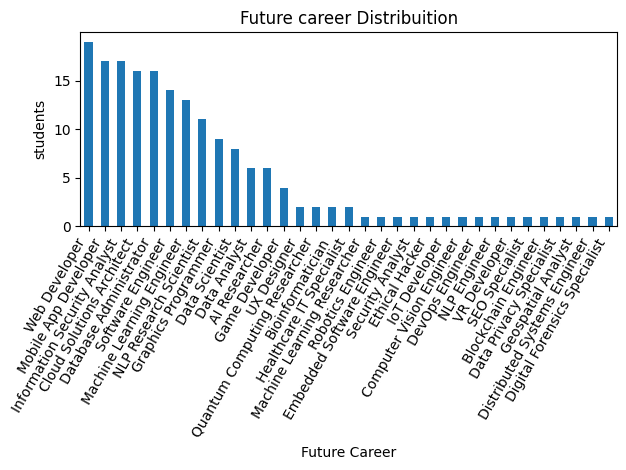

'The analysis reveals that Web Developer, Mobile App Developer, and Cybersecurity Analyst \nare the most preferred career choices among students. Emerging fields such as Data Science \nand Artificial Intelligence also show strong interest, while specialized research-oriented\ncareers attract comparatively fewer students. This reflects the growing demand for \nindustry-focused technology roles'

In [34]:
#Future Career distribuition
df["Future Career"].value_counts().plot(kind="bar")

plt.title("Future career Distribuition")
plt.xlabel("Future Career")
plt.ylabel("students")
plt.xticks(rotation=60,ha="right")
plt.tight_layout()
plt.show()
'''The analysis reveals that Web Developer, Mobile App Developer, and Cybersecurity Analyst 
are the most preferred career choices among students. Emerging fields such as Data Science 
and Artificial Intelligence also show strong interest, while specialized research-oriented
careers attract comparatively fewer students. This reflects the growing demand for 
industry-focused technology roles'''

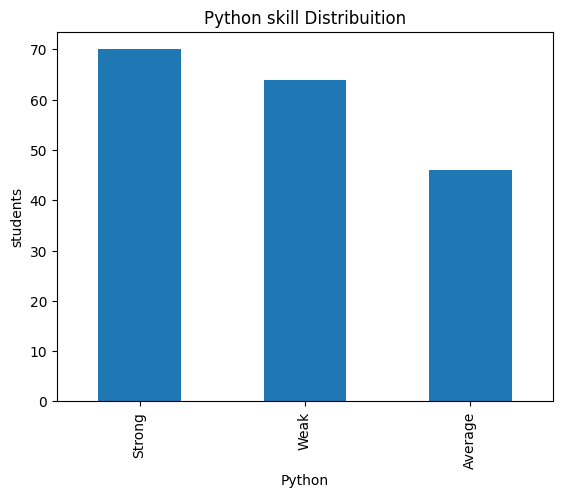

In [35]:
#Python skill distribuition
df["Python"].value_counts().plot(kind="bar")

plt.title("Python skill Distribuition")
plt.xlabel("Python")
plt.ylabel("students")
plt.show()
#most students have strong and average database skill

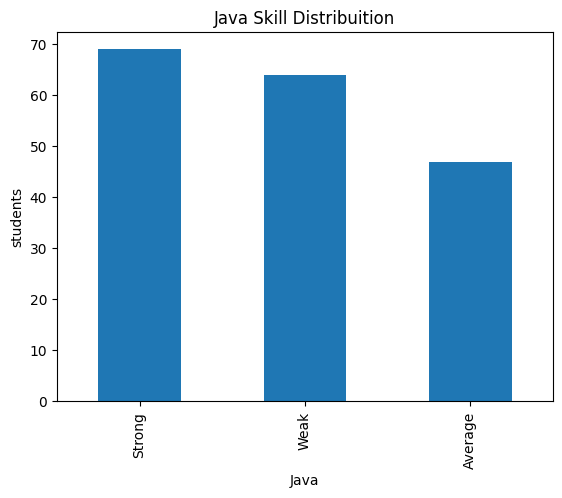

In [36]:
#Java skill distribuition
df["Java"].value_counts().plot(kind="bar")

plt.title("Java Skill Distribuition")
plt.xlabel("Java")
plt.ylabel("students")
plt.show()
#most students have strong and average database skill

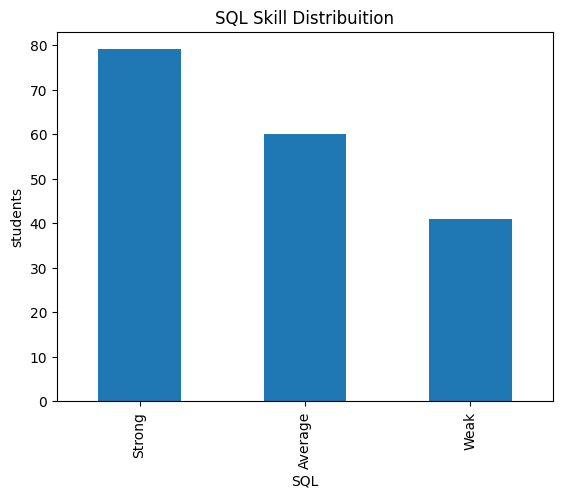

In [37]:
#SQL skill distribuition
df["SQL"].value_counts().plot(kind="bar")

plt.title("SQL Skill Distribuition")
plt.xlabel("SQL")
plt.ylabel("students")
plt.show()
#most students have strong  database skill

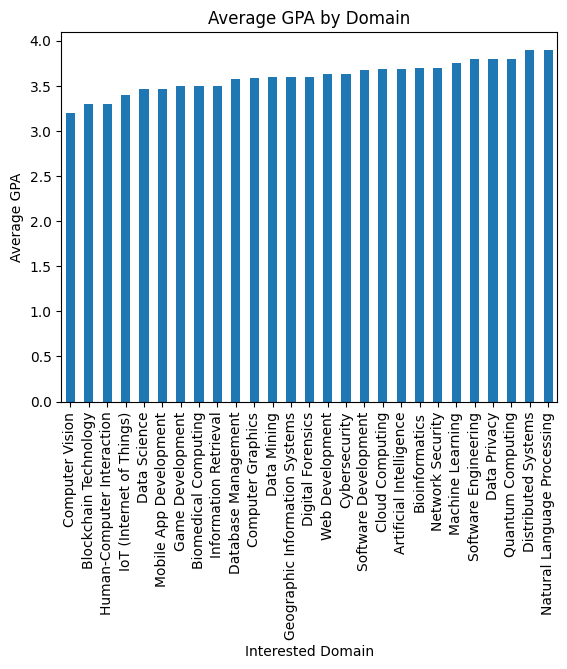

In [38]:
#Avearge GPA by Domain
df.groupby("Interested Domain")["GPA"].mean().sort_values().plot(kind="bar")

plt.title("Average GPA by Domain")
plt.xlabel("Interested Domain")
plt.ylabel("Average GPA")
plt.show()
#Students in specialized domains tend to maintain strong academic records

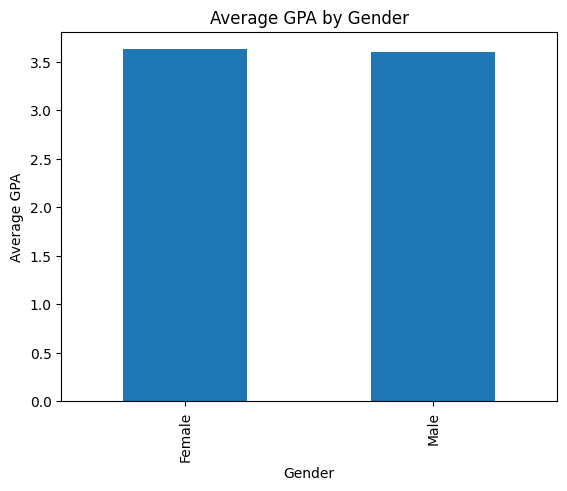

In [39]:
#Avearage GPA by Gender
df.groupby("Gender")["GPA"].mean().plot(kind="bar")
plt.title("Average GPA by Gender")
plt.xlabel("Gender")
plt.ylabel("Average GPA")
plt.show()
#Academin performance remains balanced overall

Accuracy Score:
80.56 %

Classification Report:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       0.00      0.00      0.00         1
           3       0.83      1.00      0.91         5
           5       1.00      1.00      1.00         1
           6       0.00      0.00      0.00         0
           7       1.00      1.00      1.00         1
           8       0.40      1.00      0.57         2
          11       0.00      0.00      0.00         1
          13       0.00      0.00      0.00         1
          14       0.50      1.00      0.67         1
          16       1.00      1.00      1.00         1
          17       0.00      0.00      0.00         1
          18       0.67      1.00      0.80         2
          19       0.00      0.00      0.00         1
          20       1.00      1.00      1.00         2
          22       1.00      0.80      0.89        10
          32       1.00      1.0

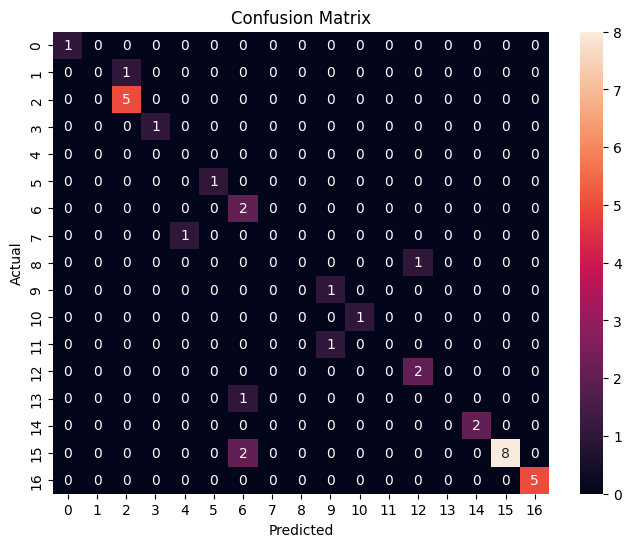


Feature Importance:

             Feature  Importance
4  Interested Domain    0.374401
5           Projects    0.261194
2                GPA    0.096958
7                SQL    0.067822
8               Java    0.058146
1                Age    0.057996
6             Python    0.054636
0             Gender    0.028847
3              Major    0.000000


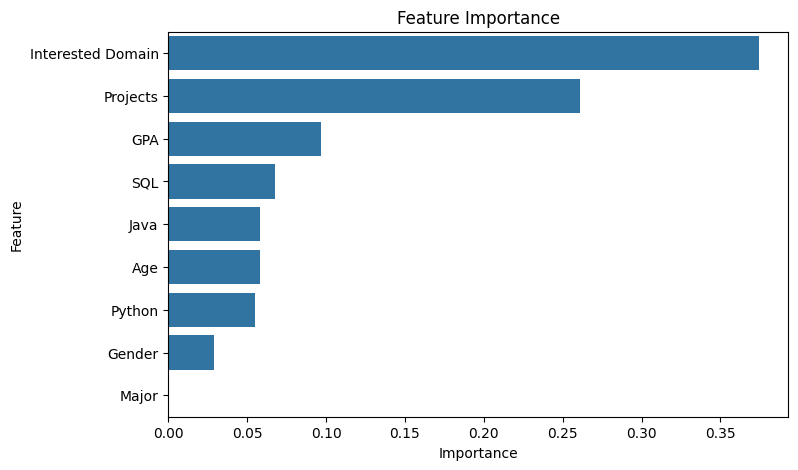

In [40]:
# ==========================
# Machine Learning Project
# Future Career Prediction
# ==========================

import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

# --------------------------
# Feature & Target Selection
# --------------------------

X = df.drop(['Student ID', 'Name', 'Future Career'], axis=1)

y = df['Future Career']

# --------------------------
# Label Encoding
# --------------------------

le_dict = {}

for col in X.columns:
    if X[col].dtype == 'object':
        le = LabelEncoder()
        X[col] = le.fit_transform(X[col])
        le_dict[col] = le

target_encoder = LabelEncoder()
y = target_encoder.fit_transform(y)

# --------------------------
# Train Test Split
# --------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# --------------------------
# Random Forest Model
# --------------------------

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

# --------------------------
# Prediction
# --------------------------

y_pred = model.predict(X_test)

# --------------------------
# Accuracy
# --------------------------

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy Score:")
print(round(accuracy * 100, 2), "%")

# --------------------------
# Classification Report
# --------------------------

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred
    )
)

# --------------------------
# Confusion Matrix
# --------------------------

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d'
)

plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

# --------------------------
# Feature Importance
# --------------------------

importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print("\nFeature Importance:\n")
print(importance)

# --------------------------
# Feature Importance Plot
# --------------------------

plt.figure(figsize=(8,5))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance')

plt.show()